# Calibrating the intervention strength of `tabicl_rca_prior` with an MMD two-sample test

We draw ~1000 random prior episodes per setting, and for each episode run an **RBF-kernel MMD permutation test** between the observational window and the interventional window (in the same obs-only-normalised representation the model consumes).

For a grid of intervention magnitudes we report:

| metric | meaning |
|---|---|
| `reject_rate` | fraction of episodes where the MMD test rejects `H0: P_obs == P_int` at α = 0.05 &mdash; **detectability** |
| `mmd_full` / `mmd_rc` | mean MMD² over the full window / over the root-cause column only |
| `shift_rc / shift_desc / shift_other` | mean `|E[int] - E[obs]|` (z-units) at the root cause / its descendants / the untouched nodes |

**A good threshold** = the smallest magnitude with `reject_rate` ≈ 1 while `shift_other` stays at the noise floor (≈ 0.1).

Interventions swept:
* `weight` &mdash; `y' = mu + (±)factor·(y - mu)` (gain / sign change) &rarr; `weight_change_range`
* `shift` &mdash; `y' = y + sigma·std_obs` &rarr; `shift_sigma_range`
* `do` &mdash; pin to `mu ± sigma·std_obs`, variance &rarr; 0 &rarr; `stuck_sigma_range`
* `cascade` &mdash; causRCA-style: RC shifts at t=0 for the whole window; a descendant `d` hops away only shifts from step `d·delay_per_hop` and with magnitude `·attenuation^d`. Short window. &rarr; `cascade_sigma_range`

Notes:
* The sweep runs with AR(1) noise and the near-constant *availability* mode **off** (`iid_only=True`): the permutation test assumes exchangeable samples. At magnitude 1.0 (weight) / sigma 0 (shift/do/cascade) the test should reject at ≈ α &mdash; the built-in calibration check.
* `fast_equations=True` drops the slow tree-SCM share from the function mixture.
* Section 6 is a **separate** sanity check for the sparse full-scale-causRCA embedding (not a magnitude sweep).

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from prim.data.tabicl_rca_prior import TabICLPriorConfig
from prim.data.prior_mmd_calibration import run_sweep, recommend_threshold

pd.set_option("display.precision", 3)

# ---- knobs -------------------------------------------------------------
QUICK = False                 # True -> ~fast pass, False -> ~1000 episodes/sweep
N_EPISODES = 40 if QUICK else 110
FAST_EQUATIONS = True         # False = include tree-SCM (slow)

BASE = TabICLPriorConfig(n_nodes_range=(12, 22), max_nodes=50)

WEIGHT_MAGS  = (1.0, 1.25, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0)
SHIFT_MAGS   = (0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 4.0)
DO_MAGS      = (0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0)
CASCADE_MAGS = (0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0)
print(f"episodes per sweep point: {N_EPISODES}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
episodes per sweep point: 110


## 1. Soft weight-change intervention  (`weight_change_range`)

No `flip` = pure variance / gain change; that is the weakest signal, so it needs the largest magnitude to be detected.

In [3]:
rows_w = run_sweep(kind="weight", magnitudes=WEIGHT_MAGS, n_episodes=N_EPISODES,
                   flip=False, fast_equations=FAST_EQUATIONS, base_config=BASE, seed=0)
df_w = pd.DataFrame(rows_w)
df_w

weight flip=0 mag= 1.00  n= 110  reject=0.15  mmd_full=0.0231  mmd_rc=0.0028  shift rc/desc/other=0.11/0.14/0.12
weight flip=0 mag= 1.25  n= 110  reject=0.22  mmd_full=0.0304  mmd_rc=0.0210  shift rc/desc/other=0.18/0.19/0.15
weight flip=0 mag= 1.50  n= 110  reject=0.31  mmd_full=0.0190  mmd_rc=0.0526  shift rc/desc/other=0.23/0.17/0.14
weight flip=0 mag= 2.00  n= 110  reject=0.61  mmd_full=0.0263  mmd_rc=0.0961  shift rc/desc/other=0.32/0.21/0.12
weight flip=0 mag= 2.50  n= 110  reject=0.89  mmd_full=0.0648  mmd_rc=0.1679  shift rc/desc/other=0.55/0.35/0.14
weight flip=0 mag= 3.00  n= 110  reject=0.88  mmd_full=0.0569  mmd_rc=0.1866  shift rc/desc/other=0.48/0.33/0.12
weight flip=0 mag= 4.00  n= 110  reject=0.88  mmd_full=0.0790  mmd_rc=0.2497  shift rc/desc/other=0.76/0.34/0.13
weight flip=0 mag= 5.00  n= 110  reject=0.95  mmd_full=0.1040  mmd_rc=0.3181  shift rc/desc/other=0.77/0.52/0.12
weight flip=0 mag= 6.00  n= 110  reject=0.92  mmd_full=0.1325  mmd_rc=0.3608  shift rc/desc/othe

,kind,flip,magnitude,n,reject_rate,mmd_full,mmd_full_p10,mmd_rc,shift_rc,shift_desc,shift_other
0,weight,False,1.00,110,0.145,0.023,-2.716e-03,0.003,0.110,0.145,0.124
1,weight,False,1.25,110,0.218,0.030,-2.071e-03,0.021,0.177,0.188,0.148
2,weight,False,1.50,110,0.309,0.019,-1.018e-03,0.053,0.233,0.169,0.136
3,weight,False,2.00,110,0.609,0.026,1.965e-04,0.096,0.323,0.211,0.118
4,weight,False,2.50,110,0.891,0.065,4.072e-03,0.168,0.550,0.345,0.136
5,weight,False,3.00,110,0.882,0.057,3.572e-03,0.187,0.476,0.332,0.122
6,weight,False,4.00,110,0.882,0.079,2.981e-03,0.250,0.762,0.342,0.130
7,weight,False,5.00,110,0.945,0.104,1.163e-02,0.318,0.772,0.519,0.121
8,weight,False,6.00,110,0.918,0.133,6.727e-03,0.361,0.813,0.507,0.130


In [4]:
rows_wf = run_sweep(kind="weight", magnitudes=WEIGHT_MAGS, n_episodes=N_EPISODES,
                    flip=True, fast_equations=FAST_EQUATIONS, base_config=BASE, seed=1)
df_wf = pd.DataFrame(rows_wf)
df_wf

weight flip=1 mag= 1.00  n= 110  reject=0.29  mmd_full=0.0261  mmd_rc=0.0388  shift rc/desc/other=0.14/0.14/0.12
weight flip=1 mag= 1.25  n= 110  reject=0.47  mmd_full=0.0302  mmd_rc=0.0609  shift rc/desc/other=0.22/0.19/0.14
weight flip=1 mag= 1.50  n= 110  reject=0.46  mmd_full=0.0437  mmd_rc=0.0808  shift rc/desc/other=0.29/0.23/0.13
weight flip=1 mag= 2.00  n= 110  reject=0.69  mmd_full=0.0440  mmd_rc=0.1187  shift rc/desc/other=0.37/0.24/0.14
weight flip=1 mag= 2.50  n= 110  reject=0.77  mmd_full=0.0483  mmd_rc=0.1339  shift rc/desc/other=0.47/0.22/0.13
weight flip=1 mag= 3.00  n= 110  reject=0.85  mmd_full=0.0494  mmd_rc=0.1939  shift rc/desc/other=0.51/0.28/0.12
weight flip=1 mag= 4.00  n= 110  reject=0.88  mmd_full=0.0899  mmd_rc=0.2429  shift rc/desc/other=0.69/0.45/0.12
weight flip=1 mag= 5.00  n= 110  reject=0.94  mmd_full=0.1167  mmd_rc=0.3321  shift rc/desc/other=0.88/0.47/0.12
weight flip=1 mag= 6.00  n= 110  reject=0.97  mmd_full=0.1473  mmd_rc=0.3833  shift rc/desc/othe

,kind,flip,magnitude,n,reject_rate,mmd_full,mmd_full_p10,mmd_rc,shift_rc,shift_desc,shift_other
0,weight,True,1.00,110,0.291,0.026,-1.859e-03,0.039,0.136,0.145,0.121
1,weight,True,1.25,110,0.473,0.030,-1.745e-03,0.061,0.219,0.193,0.139
2,weight,True,1.50,110,0.464,0.044,-4.119e-04,0.081,0.293,0.228,0.131
3,weight,True,2.00,110,0.691,0.044,5.020e-04,0.119,0.365,0.238,0.136
4,weight,True,2.50,110,0.773,0.048,1.427e-03,0.134,0.471,0.221,0.127
5,weight,True,3.00,110,0.855,0.049,2.914e-03,0.194,0.505,0.278,0.120
6,weight,True,4.00,110,0.882,0.090,2.838e-03,0.243,0.693,0.445,0.123
7,weight,True,5.00,110,0.936,0.117,1.354e-02,0.332,0.876,0.466,0.120
8,weight,True,6.00,110,0.973,0.147,1.656e-02,0.383,1.001,0.443,0.123


## 2. Mean-shift intervention  (`shift_sigma_range`)

In [5]:
rows_s = run_sweep(kind="shift", magnitudes=SHIFT_MAGS, n_episodes=N_EPISODES,
                   fast_equations=FAST_EQUATIONS, base_config=BASE, seed=2)
df_s = pd.DataFrame(rows_s)
df_s

shift  flip=0 mag= 0.00  n= 110  reject=0.12  mmd_full=0.0171  mmd_rc=0.0011  shift rc/desc/other=0.12/0.15/0.12
shift  flip=0 mag= 0.50  n= 110  reject=0.66  mmd_full=0.0255  mmd_rc=0.0901  shift rc/desc/other=0.51/0.23/0.12
shift  flip=0 mag= 1.00  n= 110  reject=0.99  mmd_full=0.0550  mmd_rc=0.2283  shift rc/desc/other=1.00/0.42/0.13
shift  flip=0 mag= 1.50  n= 110  reject=0.97  mmd_full=0.0805  mmd_rc=0.3914  shift rc/desc/other=1.38/0.48/0.12
shift  flip=0 mag= 2.00  n= 110  reject=1.00  mmd_full=0.1265  mmd_rc=0.5451  shift rc/desc/other=1.79/0.59/0.13
shift  flip=0 mag= 2.50  n= 110  reject=0.98  mmd_full=0.1949  mmd_rc=0.6910  shift rc/desc/other=2.23/0.68/0.16
shift  flip=0 mag= 3.00  n= 110  reject=0.98  mmd_full=0.2300  mmd_rc=0.8443  shift rc/desc/other=2.91/0.73/0.13
shift  flip=0 mag= 4.00  n= 110  reject=1.00  mmd_full=0.2882  mmd_rc=1.0067  shift rc/desc/other=3.12/0.90/0.14


,kind,flip,magnitude,n,reject_rate,mmd_full,mmd_full_p10,mmd_rc,shift_rc,shift_desc,shift_other
0,shift,False,0.0,110,0.118,0.017,-0.003,0.001,0.119,0.148,0.121
1,shift,False,0.5,110,0.664,0.026,0.001,0.090,0.509,0.233,0.121
2,shift,False,1.0,110,0.991,0.055,0.012,0.228,1.002,0.424,0.131
3,shift,False,1.5,110,0.973,0.080,0.016,0.391,1.376,0.482,0.115
4,shift,False,2.0,110,1.000,0.127,0.038,0.545,1.787,0.585,0.131
5,shift,False,2.5,110,0.982,0.195,0.045,0.691,2.232,0.684,0.157
6,shift,False,3.0,110,0.982,0.230,0.051,0.844,2.906,0.729,0.135
7,shift,False,4.0,110,1.000,0.288,0.057,1.007,3.116,0.900,0.143


## 3. Hard do-intervention / stuck sensor  (`stuck_sigma_range`)

Note: at magnitude 0 the node is still pinned to a constant, so variance collapse alone already makes it detectable &mdash; `reject_rate` at 0 is well above α.

In [6]:
rows_d = run_sweep(kind="do", magnitudes=DO_MAGS, n_episodes=N_EPISODES,
                   fast_equations=FAST_EQUATIONS, base_config=BASE, seed=3)
df_d = pd.DataFrame(rows_d)
df_d

do     flip=0 mag= 0.00  n= 110  reject=0.55  mmd_full=0.0436  mmd_rc=0.3691  shift rc/desc/other=0.17/0.30/0.13
do     flip=0 mag= 0.50  n= 110  reject=0.87  mmd_full=0.0434  mmd_rc=0.4379  shift rc/desc/other=0.52/0.32/0.13
do     flip=0 mag= 1.00  n= 110  reject=0.98  mmd_full=0.0752  mmd_rc=0.5732  shift rc/desc/other=0.97/0.43/0.12
do     flip=0 mag= 1.50  n= 110  reject=1.00  mmd_full=0.1235  mmd_rc=0.7477  shift rc/desc/other=1.43/0.62/0.11
do     flip=0 mag= 2.00  n= 110  reject=0.98  mmd_full=0.1648  mmd_rc=0.8986  shift rc/desc/other=1.82/0.74/0.11
do     flip=0 mag= 3.00  n= 110  reject=0.98  mmd_full=0.2882  mmd_rc=1.0439  shift rc/desc/other=2.67/0.96/0.12
do     flip=0 mag= 4.00  n= 110  reject=0.99  mmd_full=0.3672  mmd_rc=1.1314  shift rc/desc/other=3.35/1.12/0.12


,kind,flip,magnitude,n,reject_rate,mmd_full,mmd_full_p10,mmd_rc,shift_rc,shift_desc,shift_other
0,do,False,0.0,110,0.545,0.044,-0.001,0.369,0.174,0.302,0.126
1,do,False,0.5,110,0.873,0.043,0.003,0.438,0.524,0.319,0.127
2,do,False,1.0,110,0.982,0.075,0.013,0.573,0.973,0.434,0.125
3,do,False,1.5,110,1.000,0.124,0.023,0.748,1.425,0.624,0.114
4,do,False,2.0,110,0.982,0.165,0.047,0.899,1.823,0.740,0.106
5,do,False,3.0,110,0.982,0.288,0.033,1.044,2.673,0.961,0.118
6,do,False,4.0,110,0.991,0.367,0.066,1.131,3.348,1.115,0.123


## 4. Cascade intervention  (`cascade_sigma_range`) &mdash; causRCA-style

The root cause carries the full `cascade_sigma` shift; descendants are attenuated and delayed. Check that `shift_rc` ≫ `shift_desc` ≫ `shift_other` &mdash; that gradient is what lets the model rank *root cause* over *alarm*.

The MMD test here runs on the short cascade window (`cascade_n_int_range`, default `(8, 45)`), so it has fewer samples and slightly less power than the other sweeps.

In [7]:
rows_c = run_sweep(kind="cascade", magnitudes=CASCADE_MAGS, n_episodes=N_EPISODES,
                   fast_equations=FAST_EQUATIONS, base_config=BASE, seed=4)
df_c = pd.DataFrame(rows_c)
df_c

cascade flip=0 mag= 0.00  n= 110  reject=0.15  mmd_full=0.0082  mmd_rc=0.0096  shift rc/desc/other=0.23/0.21/0.19
cascade flip=0 mag= 0.50  n= 110  reject=0.26  mmd_full=0.0222  mmd_rc=0.1691  shift rc/desc/other=0.53/0.26/0.20
cascade flip=0 mag= 1.00  n= 110  reject=0.73  mmd_full=0.0384  mmd_rc=0.2495  shift rc/desc/other=0.97/0.32/0.19
cascade flip=0 mag= 1.50  n= 110  reject=0.97  mmd_full=0.0778  mmd_rc=0.4740  shift rc/desc/other=1.51/0.46/0.17
cascade flip=0 mag= 2.00  n= 110  reject=1.00  mmd_full=0.1048  mmd_rc=0.7207  shift rc/desc/other=2.00/0.54/0.19
cascade flip=0 mag= 3.00  n= 110  reject=1.00  mmd_full=0.2122  mmd_rc=1.0030  shift rc/desc/other=3.03/0.73/0.18
cascade flip=0 mag= 4.00  n= 110  reject=1.00  mmd_full=0.3393  mmd_rc=1.2139  shift rc/desc/other=3.96/1.09/0.20
cascade flip=0 mag= 5.00  n= 110  reject=1.00  mmd_full=0.4831  mmd_rc=1.3046  shift rc/desc/other=5.02/1.29/0.19


,kind,flip,magnitude,n,reject_rate,mmd_full,mmd_full_p10,mmd_rc,shift_rc,shift_desc,shift_other
0,cascade,False,0.0,110,0.145,0.008,-0.010,0.010,0.232,0.209,0.192
1,cascade,False,0.5,110,0.264,0.022,-0.005,0.169,0.527,0.259,0.197
2,cascade,False,1.0,110,0.727,0.038,0.010,0.250,0.972,0.324,0.191
3,cascade,False,1.5,110,0.973,0.078,0.037,0.474,1.505,0.459,0.170
4,cascade,False,2.0,110,1.000,0.105,0.055,0.721,1.996,0.544,0.191
5,cascade,False,3.0,110,1.000,0.212,0.136,1.003,3.026,0.732,0.184
6,cascade,False,4.0,110,1.000,0.339,0.220,1.214,3.958,1.095,0.196
7,cascade,False,5.0,110,1.000,0.483,0.334,1.305,5.021,1.294,0.191


## 5. Plots

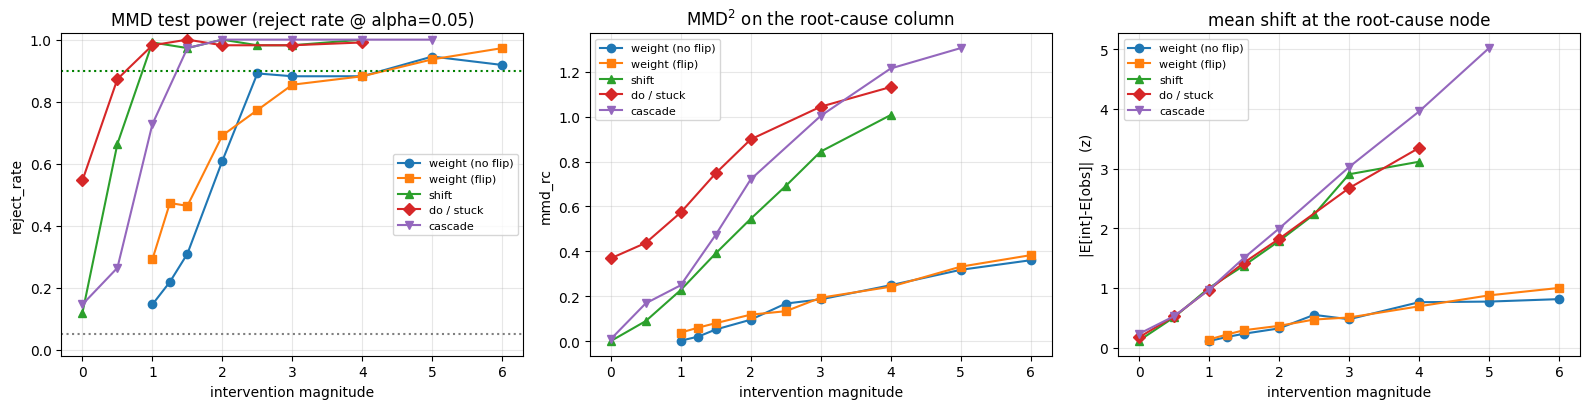

In [8]:
series = [
    ("weight (no flip)", df_w,  "o-"),
    ("weight (flip)",    df_wf, "s-"),
    ("shift",            df_s,  "^-"),
    ("do / stuck",       df_d,  "D-"),
    ("cascade",          df_c,  "v-"),
]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for name, d, fmt in series:
    ax[0].plot(d["magnitude"], d["reject_rate"], fmt, label=name)
    ax[1].plot(d["magnitude"], d["mmd_rc"],      fmt, label=name)
    ax[2].plot(d["magnitude"], d["shift_rc"],    fmt, label=name)

ax[0].axhline(0.05, ls=":", c="gray"); ax[0].axhline(0.9, ls=":", c="green")
ax[0].set_title("MMD test power (reject rate @ alpha=0.05)"); ax[0].set_ylabel("reject_rate"); ax[0].set_ylim(-0.02, 1.02)
ax[1].set_title("MMD$^2$ on the root-cause column"); ax[1].set_ylabel("mmd_rc")
ax[2].set_title("mean shift at the root-cause node"); ax[2].set_ylabel("|E[int]-E[obs]|  (z)")
for a in ax:
    a.set_xlabel("intervention magnitude"); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

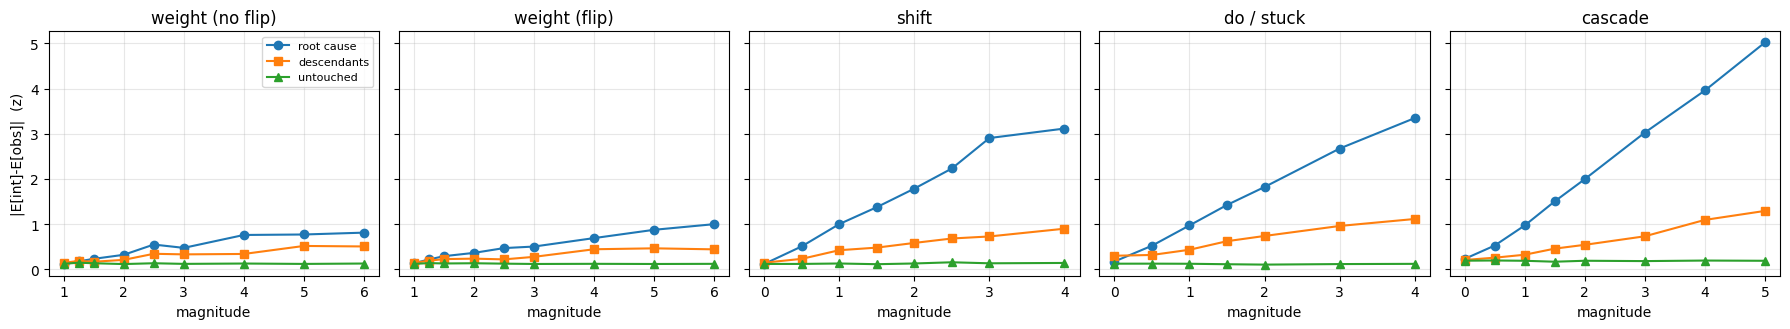

In [9]:
# localisation check: the shift must stay on the causal cone (rc + descendants),
# not leak to untouched nodes.
fig, ax = plt.subplots(1, len(series), figsize=(18, 3.4), sharey=True)
for a, (name, d, _) in zip(ax, series):
    a.plot(d["magnitude"], d["shift_rc"],    "o-", label="root cause")
    a.plot(d["magnitude"], d["shift_desc"],  "s-", label="descendants")
    a.plot(d["magnitude"], d["shift_other"], "^-", label="untouched")
    a.set_title(name); a.set_xlabel("magnitude"); a.grid(alpha=0.3)
ax[0].set_ylabel("|E[int]-E[obs]|  (z)"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Sparse full-scale causRCA sanity check

Not a magnitude sweep &mdash; a structural check that the sparse embedding (small active SCM in a grid of constant columns) behaves: silent columns stay ~0 in both windows, the root cause and symptom land inside the active subgraph, and the cascade hop gradient survives.

In [10]:
import networkx as nx
from prim.data.tabicl_rca_prior import generate_rca_episode

# force sparse + cascade, large grid (~full-scale causRCA)
cfg_sparse = TabICLPriorConfig(
    n_nodes_range=(60, 95), max_nodes=100,
    sparse_embed_prob=1.0, intervention_mix=(0, 0, 0, 0, 1),
    temporal_autocorr_prob=0.0, availability_prob=0.0,
)

rows, hop = [], {h: [] for h in range(5)}
for s in range(120):
    ep = generate_rca_episode(config=cfg_sparse, seed=7000 + s)
    k = ep["n_nodes"]
    obs = ep["observational_data"][:, :k]; intr = ep["interventional_data"][:, :k]
    active = (obs.std(0) > 1e-3) | (np.abs(obs).max(0) > 1e-3)
    rc, sym = ep["intervention_node"], ep["symptom_node"]
    dz = np.abs(intr.mean(0) - obs.mean(0))
    rows.append(dict(k=k, active=int(active.sum()), silent=int(k - active.sum()),
                     rc_in_active=bool(active[rc]), sym_in_active=bool(active[sym]),
                     max_silent_shift=float(dz[~active].max()) if (~active).any() else 0.0,
                     shift_rc=float(dz[rc])))
    g = nx.DiGraph(); g.add_nodes_from(range(k)); g.add_edges_from(ep["dag_edges"])
    for v, d in nx.single_source_shortest_path_length(g, rc).items():
        if d < 5:
            hop[d].append(dz[v])

diag = pd.DataFrame(rows)
print("grid size            :", diag["k"].min(), "-", diag["k"].max())
print("active nodes  (mean)  :", round(diag["active"].mean(), 1))
print("silent nodes  (mean)  :", round(diag["silent"].mean(), 1))
print("rc  inside active  %  :", round(100 * diag["rc_in_active"].mean(), 1))
print("sym inside active  %  :", round(100 * diag["sym_in_active"].mean(), 1))
print("max |shift| on a silent column (mean):", round(diag["max_silent_shift"].mean(), 4), " (want ~0)")
print()
for h in range(5):
    if hop[h]:
        print(f"cascade |shift| at hop {h}: {np.mean(hop[h]):.2f}   (n={len(hop[h])})")

grid size            : 60 - 95
active nodes  (mean)  : 39.1
silent nodes  (mean)  : 37.8
rc  inside active  %  : 100.0
sym inside active  %  : 100.0
max |shift| on a silent column (mean): 0.0  (want ~0)

cascade |shift| at hop 0: 5.55   (n=120)
cascade |shift| at hop 1: 1.56   (n=453)
cascade |shift| at hop 2: 0.70   (n=150)
cascade |shift| at hop 3: 0.40   (n=66)
cascade |shift| at hop 4: 0.25   (n=22)


## 7. Recommended thresholds &rarr; edit `TabICLPriorConfig`

In [11]:
targets = [
    ("weight (no flip)", rows_w,  "weight_change_range"),
    ("weight (flip)",    rows_wf, "weight_change_range"),
    ("shift",            rows_s,  "shift_sigma_range"),
    ("do / stuck",       rows_d,  "stuck_sigma_range"),
    ("cascade",          rows_c,  "cascade_sigma_range"),
]
for name, rows, field in targets:
    t90 = recommend_threshold(rows, 0.90)
    t95 = recommend_threshold(rows, 0.95)
    print(f"{name:18s} [{field:20s}]  reject>=0.90 @ {t90}   reject>=0.95 @ {t95}")

print("\nEdit prim/data/tabicl_rca_prior.py -> TabICLPriorConfig:")
print("  weight_change_range = (<t90_flip>, <t90_flip>+4)   # lean on flip; noflip plateaus <0.95")
print("  shift_sigma_range   = (<t90>, 4.0)")
print("  stuck_sigma_range   = (<t90>, 4.0)")
print("  cascade_sigma_range = (<t90>, <t90>+4)")
print("\nPick the LOWER bound at the reject>=0.9 magnitude so the weakest sampled")
print("fault is still ~always detectable; keep an upper bound above it for curriculum.")
print("weight-no-flip never reaches reject>=0.95 (gain-only signal has a ceiling) --")
print("either raise weight_flip_prob or shift intervention_mix toward shift/do/cascade.")

weight (no flip)   [weight_change_range ]  reject>=0.90 @ 5.0   reject>=0.95 @ None
weight (flip)      [weight_change_range ]  reject>=0.90 @ 5.0   reject>=0.95 @ 6.0
shift              [shift_sigma_range   ]  reject>=0.90 @ 1.0   reject>=0.95 @ 1.0
do / stuck         [stuck_sigma_range   ]  reject>=0.90 @ 1.0   reject>=0.95 @ 1.0
cascade            [cascade_sigma_range ]  reject>=0.90 @ 1.5   reject>=0.95 @ 1.5

Edit prim/data/tabicl_rca_prior.py -> TabICLPriorConfig:
  weight_change_range = (<t90_flip>, <t90_flip>+4)   # lean on flip; noflip plateaus <0.95
  shift_sigma_range   = (<t90>, 4.0)
  stuck_sigma_range   = (<t90>, 4.0)
  cascade_sigma_range = (<t90>, <t90>+4)

Pick the LOWER bound at the reject>=0.9 magnitude so the weakest sampled
fault is still ~always detectable; keep an upper bound above it for curriculum.
weight-no-flip never reaches reject>=0.95 (gain-only signal has a ceiling) --
either raise weight_flip_prob or shift intervention_mix toward shift/do/cascade.
